# Defense Score Tuning (Recalled Species)

The current defense score (`load_correlated_immunity_genes_plates_1_to_5.ipynb`):
- **Candidate genes:** immune genes, i.e. genes under the defense GO terms plus Luke's non-self-recognition set ("GO", 663 expressed) and the shared flg22-induced genes ("FLG", 868).
- **Selection:** Pearson r > 0.4 between TPM and raw bacterial load (`ham16s`) across the 223 seasonal samples, giving 148 genes.
- **Score:** each gene's TPM z-scored across samples, then averaged.

This notebook searches for better versions by varying each choice:

| Choice | Options |
|---|---|
| Gene pool | GO, FLG, GO ∪ FLG (current), and all expressed genes (genome-wide, as a reference only: not a defense score) |
| Load used to select genes | bacterial (`ham16s`, current), fungal (`hamits`), total (mean of the two z-scored log loads) |
| Correlation statistic | Pearson on raw TPM vs raw load (current); Pearson on log2 TPM vs log10 load; Spearman; Pearson **within timepoint** (log values centred within each timepoint, so genes are chosen on plant-to-plant variation rather than the shared seasonal trend) |
| Cutoff | r > 0.2 / 0.3 / 0.4 (current) / 0.5, or the top 25 / 50 / 100 / 150 / 250 genes |
| Scoring | mean z of TPM (current); mean z of log2 TPM; correlation-weighted mean z of log2 TPM; first principal component of log2 TPM |

**Avoiding circularity.** Genes are chosen by their correlation with load, so testing the score against load on the same samples would flatter every option. Two held-out tests are used instead:
1. **Cross-validation over seasonal timepoints:** the 28 seasonal timepoints are split into 7 folds (interleaved, so each fold spans the season). Genes are selected, and z-score / PCA parameters estimated, on 6 folds; the score is computed on the held-out fold.
2. **Circadian test set:** genes are selected on all seasonal samples and the score is computed on the 203 circadian samples, a separate experiment never used for selection.

**Metrics** (on held-out samples, Spearman correlations computed **within timepoint**, i.e. after centring both variables in each timepoint, so they reflect plant-to-plant differences and not the season):
- correlation with bacterial load, fungal load and *P. viridiflava* log abundance
- |correlation| with log10 library size (lower is better: a score shouldn't track sequencing depth)
- stability of the gene set across folds (mean pairwise Jaccard)
- number of genes

All configurations are saved to `Generated_data/defense_score_tuning/`.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import contextlib
import io
from pathlib import Path
import statsmodels.formula.api as smf
from scipy.stats import zscore
import pydeseq2.default_inference
import pydeseq2.ds
import pydeseq2.dds

from scipy.stats import rankdata, spearmanr
from itertools import product
import Go_tools

###Define Thresholds
pools = ["GO", "FLG", "GO + FLG", "genome-wide (reference)"]
targets = ["bacterial load", "fungal load", "total load"]
statistics = ["pearson raw", "pearson log", "spearman", "within timepoint"]
cutoffs = [("r >", 0.2), ("r >", 0.3), ("r >", 0.4), ("r >", 0.5), ("top", 25), ("top", 50), ("top", 100), ("top", 150), ("top", 250)]
scorings = ["mean z TPM", "mean z log2 TPM", "weighted mean z log2 TPM", "PC1 log2 TPM"]
n_folds = 7
min_genes = 5
genome_wide_min_median_tpm = 1.0
log_pseudocount = 0.05
expressed_gene_reads_threshold = 2000
number_of_samples_expressed_in_threshold = 21
current_config = ("GO + FLG", "bacterial load", "pearson raw", "r >", 0.4, "mean z TPM")
output_dir = Path("/Users/michael/Data/Luke_terrace_experiment/General_data/Generated_data/defense_score_tuning")
output_dir.mkdir(parents=True, exist_ok=True)

In [2]:
transcriptome = pd.read_csv(
    "/Users/michael/Data/Luke_terrace_experiment/General_data/plate1_5_tpm_normalized.csv",
    index_col=0,
)
rows_to_drop_expression_data = [
    "A2450525897_n01_undetermined",
    "A2449446903_n01_undetermined",
    "B250508004_n01_undetermined",
    "B2449500127_n01_undetermined",
]
transcriptome = transcriptome.drop(index=rows_to_drop_expression_data)
transcriptome = transcriptome.sort_index()
metadata = pd.read_csv(
    "/Users/michael/Data/Luke_terrace_experiment/General_data/Plates_1_to_5_metadata_merged_luke.csv",
    index_col=0,
)
raw_transcriptome = pd.read_csv(
    "/Users/michael/Data/Luke_terrace_experiment/General_data/plate1_5_for_norm.csv",
    index_col=0,
)

## Get plate 5 samples and remove what they replaced from the metadata to avoid duplicates
plate_5_replacements = metadata.loc[metadata["rnaprepplate"] == "LICRNA_05"]
non_plate_5_samples = metadata.loc[metadata["rnaprepplate"] != "LICRNA_05"]
replaced_samples = non_plate_5_samples.loc[
    non_plate_5_samples["sampID"].isin(plate_5_replacements["sampID"])
]
trimmed_metadata = metadata.drop(index=replaced_samples.index)
### For remaining duplicated sampIDs, drop the transcriptome with fewer total reads
double_duplicates = (
    trimmed_metadata.loc[trimmed_metadata.duplicated(subset="sampID", keep=False)]
    .sort_values(by="Total Reads")
    .drop_duplicates(subset="sampID", keep="first")
)
trimmed_metadata = trimmed_metadata.drop(index=double_duplicates.index)
### Drop failed libraries with too few reads (e.g. LIC162 has 66 total reads)
min_total_reads = 250_000
low_read_samples = trimmed_metadata.index[trimmed_metadata["Total Reads"] < min_total_reads]
trimmed_metadata = trimmed_metadata.drop(index=low_read_samples)
print(f"Dropped {len(low_read_samples)} transcriptomes with < {min_total_reads:,} total reads")
trimmed_transcriptome = transcriptome.loc[trimmed_metadata.index]
trimmed_raw_transcriptome = raw_transcriptome.loc[trimmed_metadata.index]
print("Transcriptomes after removing replicates:", len(trimmed_metadata))

# Same gene filters as the dysbiosis DE notebook
cleaned_raw_transcriptome = trimmed_raw_transcriptome.loc[
    :, trimmed_raw_transcriptome.sum() > expressed_gene_reads_threshold
]
cleaned_raw_transcriptome = cleaned_raw_transcriptome.loc[
    :, (cleaned_raw_transcriptome > 1).sum() > number_of_samples_expressed_in_threshold
]
print("Genes kept for DESeq2:", cleaned_raw_transcriptome.shape[1])

# Defense score: only used to describe the groups, never to define them
defense_gene_list = pd.read_csv(
    "/Users/michael/Data/Luke_terrace_experiment/General_data/Generated_data/load_correlated_genes_union_GO_and_FLG_plates_1_to_5.csv"
)
defense_genes = set(defense_gene_list["gene"])
transcriptome_in_defense_gene_list = trimmed_transcriptome.loc[
    :, trimmed_transcriptome.columns.isin(defense_genes)
]
trimmed_metadata["Defense Score"] = transcriptome_in_defense_gene_list.apply(zscore).sum(
    axis=1
) / len(defense_gene_list)

# Old species-level DE genes (59, plates 1-5), for overlap
old_de_genes = set(
    pd.read_csv(
        "/Users/michael/Data/Luke_terrace_experiment/General_data/Junk_data/large_deseq_gene_list_all_plates.csv",
        header=None,
    )[0]
)

Dropped 6 transcriptomes with < 250,000 total reads
Transcriptomes after removing replicates: 426


Genes kept for DESeq2: 18032


## Species abundance (for *P. viridiflava*)

In [3]:
### Recalled species table. Species under 0.05% of a sample (AbundR == 0) are
### dropped, as in the recalled-genera table
min_abundR = 1
### Plant samples missing from the recalled-genera table (LIC148, LIC162, LIC584 have
### < 1,600 16S reads; LIC577 unknown). Kept for now: see to_revisit.txt
samples_to_drop = []  # ["LIC148", "LIC162", "LIC577", "LIC584"]
microbiome_abundance = pd.read_csv(
    "/Users/michael/Data/Luke_terrace_experiment/Oct_2026_recalled_species/lic16s_species_relabund.csv"
)
microbiome_abundance = microbiome_abundance.loc[
    (microbiome_abundance["AbundR"] >= min_abundR)
    & ~microbiome_abundance["Sample"].isin(samples_to_drop)
].copy()
# No seascirc column in the species table: circadian timepoints start with "c"
microbiome_abundance["seascirc"] = np.where(
    microbiome_abundance["timepoint"].str.startswith("c"), "circadian", "seasonal"
)
plant_microbiome = microbiome_abundance.loc[microbiome_abundance["sample.type"] == "plant"]

# Sample x species abundance as % of each sample's reads (absent species = 0)
species_abundance_matrix = pd.pivot_table(
    plant_microbiome, values="Abundance", index="Sample", columns="Species", aggfunc="sum", fill_value=0
)
species_abundance_matrix = species_abundance_matrix.div(species_abundance_matrix.sum(axis=1), axis=0) * 100
seasonal_samples = plant_microbiome.loc[plant_microbiome["seascirc"] == "seasonal", "Sample"].unique()
seasonal_prevalence = (species_abundance_matrix.loc[seasonal_samples] > 0).mean()

# Transcriptome samples, all with a microbiome profile
de_samples = trimmed_metadata.index[trimmed_metadata["sampID"].isin(species_abundance_matrix.index)]
print("Transcriptomes with a microbiome profile:", len(de_samples), "of", len(trimmed_metadata))
sample_species = species_abundance_matrix.loc[trimmed_metadata.loc[de_samples, "sampID"]].set_index(de_samples)

Transcriptomes with a microbiome profile: 426 of 426


## Candidate gene pools, loads and sample sets

In [4]:
go_term_matrix = pd.read_csv("/Users/michael/Data/Reference_data/Arabdidopsis_go_matrix_from_tair_gaf.csv", index_col=0)
go_term_names = pd.read_csv("/Users/michael/Data/Reference_data/goterm_names.csv", index_col=0)
defense_terms = pd.read_csv("/Users/michael/Data/Luke_terrace_experiment/General_data/Defense_go_terms.csv")
non_self_recognition_genes = [
    "AT1G02920", "AT1G02930", "AT1G21110", "AT1G21120", "AT1G26380", "AT1G26410",
    "AT1G26420", "AT1G35230", "AT1G64170", "AT1G65500", "AT1G76930", "AT2G19190",
    "AT2G25470", "AT2G30750", "AT2G39200", "AT2G43620", "AT3G46280", "AT4G12490",
    "AT4G12500", "AT4G23140", "AT4G23220", "AT4G28420", "AT5G24110", "AT5G64120",
]
defense_go_terms = [t for t in defense_terms["GO Term ID"].unique() if t in go_term_matrix.columns]
go_pool = set(go_term_matrix.index[(go_term_matrix[defense_go_terms] == 1).any(axis=1)]) | set(non_self_recognition_genes)
flg_genes = pd.read_csv("/Users/michael/Data/Luke_terrace_experiment/General_data/shared_flg_induced_genes.csv")
flg_pool = set(flg_genes["Arabidopsis_thaliana"].dropna().astype(str).str.strip()) - {"", "nan", "None"}

tpm = trimmed_transcriptome
tpm = tpm.loc[:, tpm.std() > 0]
log_tpm = np.log2(tpm + 1)
genome_wide_pool = set(tpm.columns[tpm.median() >= genome_wide_min_median_tpm])
pool_genes = {
    "GO": sorted(go_pool & set(tpm.columns)),
    "FLG": sorted(flg_pool & set(tpm.columns)),
    "GO + FLG": sorted((go_pool | flg_pool) & set(tpm.columns)),
    "genome-wide (reference)": sorted(genome_wide_pool | ((go_pool | flg_pool) & set(tpm.columns))),
}
all_candidate_genes = pool_genes["genome-wide (reference)"]
print({pool: len(genes) for pool, genes in pool_genes.items()})

load_table = pd.read_csv("/Users/michael/Data/Luke_terrace_experiment/Microbiome/lic2024_ham_16S_ITS.csv", index_col=0)
sample_ids = trimmed_metadata["sampID"]
raw_bacterial = sample_ids.map(load_table["ham16s"])
raw_fungal = sample_ids.map(load_table["hamits"])
log_bacterial = np.log10(raw_bacterial)
log_fungal = np.log10(raw_fungal)
log_total = ((log_bacterial - log_bacterial.mean()) / log_bacterial.std() + (log_fungal - log_fungal.mean()) / log_fungal.std()) / 2
target_values = {  # (raw scale for "pearson raw", log scale for the rest)
    "bacterial load": (raw_bacterial, log_bacterial),
    "fungal load": (raw_fungal, log_fungal),
    "total load": (log_total, log_total),
}
viridiflava = np.log10(
    sample_ids.map(species_abundance_matrix["s__Pseudomonas_E_647464 viridiflava"]) + log_pseudocount
)
log_library_size = np.log10(trimmed_metadata["Total Reads"].astype(float))
timepoint = trimmed_metadata["timepoint"]

has_load = log_bacterial.notna() & log_fungal.notna()
seasonal = trimmed_metadata.index[(trimmed_metadata["Experiment Type"] == "Long Term") & has_load]
circadian = trimmed_metadata.index[(trimmed_metadata["Experiment Type"] != "Long Term") & has_load]
seasonal_timepoints = sorted(timepoint[seasonal].unique())
fold_of_timepoint = {tp: i % n_folds for i, tp in enumerate(seasonal_timepoints)}
fold = timepoint[seasonal].map(fold_of_timepoint)
print(f"Seasonal samples: {len(seasonal)} ({len(seasonal_timepoints)} timepoints, {n_folds} folds); circadian test samples: {len(circadian)}")

{'GO': 657, 'FLG': 865, 'GO + FLG': 1416, 'genome-wide (reference)': 14946}
Seasonal samples: 222 (28 timepoints, 7 folds); circadian test samples: 201


## Gene-load correlations

For each training set (7 cross-validation folds + all seasonal samples), the correlation of every candidate gene with each load, for each statistic.

In [5]:
def column_correlation(matrix, vector):
    """Pearson r of each column of matrix with vector (rows aligned, no missing values)."""
    m = matrix - matrix.mean(axis=0)
    v = vector - vector.mean()
    return (m * v[:, None]).sum(axis=0) / np.sqrt((m ** 2).sum(axis=0) * (v ** 2).sum())


def centre_within(values, groups):
    frame = pd.DataFrame(values)
    return (frame - frame.groupby(groups.to_numpy()).transform("mean").to_numpy()).to_numpy()


def gene_correlations(train):
    """{(target, statistic): Series of r over all_candidate_genes} for one training set."""
    tpm_train = tpm.loc[train, all_candidate_genes].to_numpy()
    log_train = log_tpm.loc[train, all_candidate_genes].to_numpy()
    rank_train = np.apply_along_axis(rankdata, 0, tpm_train)
    log_centred = centre_within(log_train, timepoint[train])
    out = {}
    for target, (raw, logged) in target_values.items():
        raw_t, log_t = raw[train].to_numpy(), logged[train].to_numpy()
        out[(target, "pearson raw")] = column_correlation(tpm_train, raw_t)
        out[(target, "pearson log")] = column_correlation(log_train, log_t)
        out[(target, "spearman")] = column_correlation(rank_train, rankdata(log_t))
        out[(target, "within timepoint")] = column_correlation(log_centred, centre_within(log_t[:, None], timepoint[train])[:, 0])
    return {key: pd.Series(np.nan_to_num(value, nan=0.0), index=all_candidate_genes) for key, value in out.items()}


training_sets = {f"fold {k}": seasonal[fold != k] for k in range(n_folds)}
training_sets["all seasonal"] = seasonal
correlations = {name: gene_correlations(train) for name, train in training_sets.items()}

# Sanity check: the current rule on all seasonal samples should recover the 148-gene list
current_rebuilt = set(
    correlations["all seasonal"][("bacterial load", "pearson raw")]
    .loc[pool_genes["GO + FLG"]]
    .pipe(lambda r: r.index[r > 0.4])
)
print(f"Current rule rebuilt: {len(current_rebuilt)} genes; overlap with the saved 148: {len(current_rebuilt & defense_genes)}")

/var/folders/nk/6xkk9sgn1pz4ff1b36sfq3y40000gt/T/ipykernel_16901/2845110594.py:5: RuntimeWarning: invalid value encountered in divide
  return (m * v[:, None]).sum(axis=0) / np.sqrt((m ** 2).sum(axis=0) * (v ** 2).sum())
/var/folders/nk/6xkk9sgn1pz4ff1b36sfq3y40000gt/T/ipykernel_16901/2845110594.py:5: RuntimeWarning: invalid value encountered in divide
  return (m * v[:, None]).sum(axis=0) / np.sqrt((m ** 2).sum(axis=0) * (v ** 2).sum())


/var/folders/nk/6xkk9sgn1pz4ff1b36sfq3y40000gt/T/ipykernel_16901/2845110594.py:5: RuntimeWarning: invalid value encountered in divide
  return (m * v[:, None]).sum(axis=0) / np.sqrt((m ** 2).sum(axis=0) * (v ** 2).sum())
/var/folders/nk/6xkk9sgn1pz4ff1b36sfq3y40000gt/T/ipykernel_16901/2845110594.py:5: RuntimeWarning: invalid value encountered in divide
  return (m * v[:, None]).sum(axis=0) / np.sqrt((m ** 2).sum(axis=0) * (v ** 2).sum())


/var/folders/nk/6xkk9sgn1pz4ff1b36sfq3y40000gt/T/ipykernel_16901/2845110594.py:5: RuntimeWarning: invalid value encountered in divide
  return (m * v[:, None]).sum(axis=0) / np.sqrt((m ** 2).sum(axis=0) * (v ** 2).sum())
/var/folders/nk/6xkk9sgn1pz4ff1b36sfq3y40000gt/T/ipykernel_16901/2845110594.py:5: RuntimeWarning: invalid value encountered in divide
  return (m * v[:, None]).sum(axis=0) / np.sqrt((m ** 2).sum(axis=0) * (v ** 2).sum())


/var/folders/nk/6xkk9sgn1pz4ff1b36sfq3y40000gt/T/ipykernel_16901/2845110594.py:5: RuntimeWarning: invalid value encountered in divide
  return (m * v[:, None]).sum(axis=0) / np.sqrt((m ** 2).sum(axis=0) * (v ** 2).sum())
/var/folders/nk/6xkk9sgn1pz4ff1b36sfq3y40000gt/T/ipykernel_16901/2845110594.py:5: RuntimeWarning: invalid value encountered in divide
  return (m * v[:, None]).sum(axis=0) / np.sqrt((m ** 2).sum(axis=0) * (v ** 2).sum())


/var/folders/nk/6xkk9sgn1pz4ff1b36sfq3y40000gt/T/ipykernel_16901/2845110594.py:5: RuntimeWarning: invalid value encountered in divide
  return (m * v[:, None]).sum(axis=0) / np.sqrt((m ** 2).sum(axis=0) * (v ** 2).sum())
/var/folders/nk/6xkk9sgn1pz4ff1b36sfq3y40000gt/T/ipykernel_16901/2845110594.py:5: RuntimeWarning: invalid value encountered in divide
  return (m * v[:, None]).sum(axis=0) / np.sqrt((m ** 2).sum(axis=0) * (v ** 2).sum())


/var/folders/nk/6xkk9sgn1pz4ff1b36sfq3y40000gt/T/ipykernel_16901/2845110594.py:5: RuntimeWarning: invalid value encountered in divide
  return (m * v[:, None]).sum(axis=0) / np.sqrt((m ** 2).sum(axis=0) * (v ** 2).sum())
/var/folders/nk/6xkk9sgn1pz4ff1b36sfq3y40000gt/T/ipykernel_16901/2845110594.py:5: RuntimeWarning: invalid value encountered in divide
  return (m * v[:, None]).sum(axis=0) / np.sqrt((m ** 2).sum(axis=0) * (v ** 2).sum())


... (6 outputs left out)

/var/folders/nk/6xkk9sgn1pz4ff1b36sfq3y40000gt/T/ipykernel_16901/2845110594.py:5: RuntimeWarning: invalid value encountered in divide
  return (m * v[:, None]).sum(axis=0) / np.sqrt((m ** 2).sum(axis=0) * (v ** 2).sum())
/var/folders/nk/6xkk9sgn1pz4ff1b36sfq3y40000gt/T/ipykernel_16901/2845110594.py:5: RuntimeWarning: invalid value encountered in divide
  return (m * v[:, None]).sum(axis=0) / np.sqrt((m ** 2).sum(axis=0) * (v ** 2).sum())
/var/folders/nk/6xkk9sgn1pz4ff1b36sfq3y40000gt/T/ipykernel_16901/2845110594.py:5: RuntimeWarning: invalid value encountered in divide
  return (m * v[:, None]).sum(axis=0) / np.sqrt((m ** 2).sum(axis=0) * (v ** 2).sum())
/var/folders/nk/6xkk9sgn1pz4ff1b36sfq3y40000gt/T/ipykernel_16901/2845110594.py:5: RuntimeWarning: invalid value encountered in divide
  return (m * v[:, None]).sum(axis=0) / np.sqrt((m ** 2).sum(axis=0) * (v ** 2).sum())


/var/folders/nk/6xkk9sgn1pz4ff1b36sfq3y40000gt/T/ipykernel_16901/2845110594.py:5: RuntimeWarning: invalid value encountered in divide
  return (m * v[:, None]).sum(axis=0) / np.sqrt((m ** 2).sum(axis=0) * (v ** 2).sum())
/var/folders/nk/6xkk9sgn1pz4ff1b36sfq3y40000gt/T/ipykernel_16901/2845110594.py:5: RuntimeWarning: invalid value encountered in divide
  return (m * v[:, None]).sum(axis=0) / np.sqrt((m ** 2).sum(axis=0) * (v ** 2).sum())


/var/folders/nk/6xkk9sgn1pz4ff1b36sfq3y40000gt/T/ipykernel_16901/2845110594.py:5: RuntimeWarning: invalid value encountered in divide
  return (m * v[:, None]).sum(axis=0) / np.sqrt((m ** 2).sum(axis=0) * (v ** 2).sum())
/var/folders/nk/6xkk9sgn1pz4ff1b36sfq3y40000gt/T/ipykernel_16901/2845110594.py:5: RuntimeWarning: invalid value encountered in divide
  return (m * v[:, None]).sum(axis=0) / np.sqrt((m ** 2).sum(axis=0) * (v ** 2).sum())


Current rule rebuilt: 148 genes; overlap with the saved 148: 148


## Scoring held-out samples

In [6]:
def select_genes(r, pool, cutoff_kind, cutoff_value):
    r = r.loc[pool_genes[pool]]
    if cutoff_kind == "r >":
        return r.index[r > cutoff_value]
    return r.sort_values(ascending=False).index[: int(cutoff_value)]


def score_samples(genes, scoring, train, test, r):
    if scoring == "mean z TPM":
        values = tpm.loc[:, genes]
    else:
        values = log_tpm.loc[:, genes]
    mean, sd = values.loc[train].mean(), values.loc[train].std().replace(0, np.nan)
    z_test = ((values.loc[test] - mean) / sd).fillna(0)
    if scoring in ("mean z TPM", "mean z log2 TPM"):
        return z_test.mean(axis=1)
    if scoring == "weighted mean z log2 TPM":
        weights = r.loc[genes].clip(lower=0)
        weights = weights / weights.sum() if weights.sum() > 0 else pd.Series(1 / len(genes), index=genes)
        return z_test.mul(weights, axis=1).sum(axis=1)
    # PC1 fitted on the training samples, signed to follow the mean
    z_train = ((values.loc[train] - mean) / sd).fillna(0)
    _, _, vt = np.linalg.svd(z_train.to_numpy() - z_train.to_numpy().mean(axis=0), full_matrices=False)
    loading = pd.Series(vt[0], index=genes)
    if loading.sum() < 0:
        loading = -loading
    return z_test.mul(loading, axis=1).sum(axis=1)


def within_timepoint_spearman(score, other):
    df = pd.DataFrame({"s": score, "o": other.reindex(score.index), "tp": timepoint.reindex(score.index)}).dropna()
    centred = df[["s", "o"]] - df.groupby("tp")[["s", "o"]].transform("mean")
    return spearmanr(centred["s"], centred["o"])[0]


def evaluate(score):
    return {
        "bacterial": within_timepoint_spearman(score, log_bacterial),
        "fungal": within_timepoint_spearman(score, log_fungal),
        "P. viridiflava": within_timepoint_spearman(score, viridiflava),
        "|library size|": abs(within_timepoint_spearman(score, log_library_size)),
    }

In [7]:
rows = []
gene_sets = {}
configurations = list(product(pools, targets, statistics, cutoffs, scorings))
for pool, target, statistic, (cutoff_kind, cutoff_value), scoring in configurations:
    key = (pool, target, statistic, cutoff_kind, cutoff_value, scoring)
    fold_sets, cv_scores = [], []
    for k in range(n_folds):
        r = correlations[f"fold {k}"][(target, statistic)]
        genes = select_genes(r, pool, cutoff_kind, cutoff_value)
        fold_sets.append(set(genes))
        if len(genes) >= min_genes:
            cv_scores.append(score_samples(genes, scoring, seasonal[fold != k], seasonal[fold == k], r))
    r_all = correlations["all seasonal"][(target, statistic)]
    full_genes = select_genes(r_all, pool, cutoff_kind, cutoff_value)
    gene_sets[key] = list(full_genes)
    row = {
        "pool": pool, "selected on": target, "statistic": statistic, "cutoff": f"{cutoff_kind} {cutoff_value}",
        "scoring": scoring, "n genes": len(full_genes),
        "min genes in a fold": min(len(s) for s in fold_sets),
        "fold stability (Jaccard)": np.mean([len(a & b) / max(len(a | b), 1) for i, a in enumerate(fold_sets) for b in fold_sets[i + 1:]]),
        "overlap with current 148": len(set(full_genes) & defense_genes),
    }
    if len(cv_scores) == n_folds:
        row.update({f"CV {k}": v for k, v in evaluate(pd.concat(cv_scores)).items()})
    if len(full_genes) >= min_genes:
        row.update({f"circadian {k}": v for k, v in evaluate(score_samples(full_genes, scoring, seasonal, circadian, r_all)).items()})
    rows.append(row)
tuning = pd.DataFrame(rows)
tuning["current"] = (
    (tuning["pool"] == current_config[0]) & (tuning["selected on"] == current_config[1]) & (tuning["statistic"] == current_config[2])
    & (tuning["cutoff"] == f"{current_config[3]} {current_config[4]}") & (tuning["scoring"] == current_config[5])
)
tuning["held-out bacterial (mean of CV and circadian)"] = tuning[["CV bacterial", "circadian bacterial"]].mean(axis=1)
tuning.to_csv(output_dir / "defense_score_tuning_grid.csv", index=False)
print(f"Configurations: {len(tuning)}")
tuning.loc[tuning["current"]].round(3).T

Configurations: 1728


,872
pool,GO + FLG
selected on,bacterial load
statistic,pearson raw
cutoff,r > 0.4
scoring,mean z TPM
n genes,148
min genes in a fold,79
fold stability (Jaccard),0.593
overlap with current 148,148
CV bacterial,0.26


## Results

### Each choice on its own

Average held-out within-timepoint correlation with bacterial load (CV and circadian) for each option of one choice, averaged over all the other choices. Defense pools only (genome-wide excluded).

In [8]:
defense_only = tuning.loc[tuning["pool"] != "genome-wide (reference)"]
metric_columns = ["CV bacterial", "circadian bacterial", "CV fungal", "circadian fungal", "CV P. viridiflava", "circadian P. viridiflava", "circadian |library size|"]
for choice in ["pool", "selected on", "statistic", "cutoff", "scoring"]:
    data = (defense_only if choice != "pool" else tuning).groupby(choice)[metric_columns].mean().round(3)
    print(f"\n=== {choice} ===")
    display(data)


=== pool ===


,CV bacterial,circadian bacterial,CV fungal,circadian fungal,CV P. viridiflava,circadian P. viridiflava,circadian |library size|
pool,,,,,,,
FLG,0.226,0.211,0.380,0.436,0.266,0.437,0.138
GO,0.241,0.161,0.350,0.386,0.227,0.431,0.075
GO + FLG,0.242,0.189,0.375,0.415,0.246,0.451,0.097
genome-wide (reference),0.245,0.137,0.297,0.335,0.171,0.400,0.051



=== selected on ===


,CV bacterial,circadian bacterial,CV fungal,circadian fungal,CV P. viridiflava,circadian P. viridiflava,circadian |library size|
selected on,,,,,,,
bacterial load,0.239,0.170,0.353,0.399,0.216,0.419,0.115
fungal load,0.229,0.207,0.385,0.427,0.283,0.461,0.096
total load,0.242,0.186,0.366,0.411,0.242,0.441,0.098



=== statistic ===


,CV bacterial,circadian bacterial,CV fungal,circadian fungal,CV P. viridiflava,circadian P. viridiflava,circadian |library size|
statistic,,,,,,,
pearson log,0.241,0.185,0.370,0.411,0.250,0.449,0.093
pearson raw,0.242,0.169,0.350,0.392,0.214,0.417,0.117
spearman,0.236,0.191,0.374,0.416,0.258,0.453,0.087
within timepoint,0.225,0.205,0.379,0.432,0.266,0.439,0.120



=== cutoff ===


,CV bacterial,circadian bacterial,CV fungal,circadian fungal,CV P. viridiflava,circadian P. viridiflava,circadian |library size|
cutoff,,,,,,,
r > 0.2,0.226,0.180,0.370,0.412,0.246,0.417,0.119
r > 0.3,0.239,0.197,0.377,0.427,0.251,0.444,0.111
r > 0.4,0.235,0.197,0.370,0.415,0.256,0.462,0.090
r > 0.5,0.243,0.158,0.301,0.364,0.172,0.426,0.063
top 100,0.244,0.188,0.377,0.417,0.248,0.445,0.109
top 150,0.240,0.185,0.376,0.416,0.246,0.435,0.111
top 25,0.233,0.191,0.354,0.404,0.254,0.451,0.089
top 250,0.233,0.182,0.374,0.414,0.245,0.422,0.117
top 50,0.242,0.190,0.368,0.413,0.251,0.454,0.097



=== scoring ===


,CV bacterial,circadian bacterial,CV fungal,circadian fungal,CV P. viridiflava,circadian P. viridiflava,circadian |library size|
scoring,,,,,,,
PC1 log2 TPM,0.235,0.190,0.368,0.414,0.249,0.438,0.095
mean z TPM,0.241,0.173,0.353,0.392,0.223,0.428,0.148
mean z log2 TPM,0.235,0.192,0.375,0.420,0.256,0.445,0.086
weighted mean z log2 TPM,0.236,0.193,0.375,0.421,0.257,0.448,0.085


### Best configurations

Ranked by the mean of the CV and circadian within-timepoint correlations with bacterial load, defense pools only. The current configuration is shown for comparison.

In [9]:
display_columns = [
    "pool", "selected on", "statistic", "cutoff", "scoring", "n genes", "overlap with current 148",
    "fold stability (Jaccard)", "CV bacterial", "circadian bacterial", "CV fungal", "circadian fungal",
    "CV P. viridiflava", "circadian P. viridiflava", "circadian |library size|",
]
ranked = defense_only.dropna(subset=["CV bacterial", "circadian bacterial"]).sort_values(
    "held-out bacterial (mean of CV and circadian)", ascending=False
)
current_row = tuning.loc[tuning["current"]]
current_rank = ranked.index.get_loc(current_row.index[0]) + 1 if current_row.index[0] in ranked.index else None
print(f"Current configuration ranks {current_rank} of {len(ranked)} on held-out bacterial-load correlation")
pd.concat([ranked.head(20), current_row])[display_columns].round(3)

Current configuration ranks 492 of 1152 on held-out bacterial-load correlation


,pool,selected on,statistic,cutoff,scoring,n genes,overlap with current 148,fold stability (Jaccard),CV bacterial,circadian bacterial,CV fungal,circadian fungal,CV P. viridiflava,circadian P. viridiflava,circadian |library size|
847,FLG,total load,within timepoint,top 25,PC1 log2 TPM,25,8,0.509,0.267,0.256,0.399,0.480,0.270,0.465,0.137
846,FLG,total load,within timepoint,top 25,weighted mean z log2 TPM,25,8,0.509,0.264,0.257,0.395,0.480,0.271,0.464,0.136
845,FLG,total load,within timepoint,top 25,mean z log2 TPM,25,8,0.509,0.263,0.257,0.397,0.482,0.269,0.464,0.136
1282,GO + FLG,total load,within timepoint,top 50,weighted mean z log2 TPM,50,17,0.488,0.250,0.258,0.400,0.472,0.282,0.473,0.118
1281,GO + FLG,total load,within timepoint,top 50,mean z log2 TPM,50,17,0.488,0.251,0.257,0.402,0.471,0.282,0.472,0.118
259,GO,fungal load,within timepoint,r > 0.3,PC1 log2 TPM,31,7,0.399,0.240,0.267,0.387,0.470,0.318,0.477,0.075
1283,GO + FLG,total load,within timepoint,top 50,PC1 log2 TPM,50,17,0.488,0.250,0.256,0.401,0.468,0.279,0.470,0.122
629,FLG,fungal load,pearson log,top 25,mean z log2 TPM,25,6,0.638,0.235,0.266,0.428,0.487,0.348,0.521,0.064
257,GO,fungal load,within timepoint,r > 0.3,mean z log2 TPM,31,7,0.399,0.235,0.266,0.417,0.475,0.324,0.479,0.070
413,GO,total load,within timepoint,top 25,mean z log2 TPM,25,10,0.491,0.231,0.269,0.393,0.451,0.300,0.482,0.089


In [10]:
print("Genome-wide reference (best 5): how much is lost by restricting to defense genes")
tuning.loc[tuning["pool"] == "genome-wide (reference)"].sort_values(
    "held-out bacterial (mean of CV and circadian)", ascending=False
).head(5)[display_columns].round(3)

Genome-wide reference (best 5): how much is lost by restricting to defense genes


,pool,selected on,statistic,cutoff,scoring,n genes,overlap with current 148,fold stability (Jaccard),CV bacterial,circadian bacterial,CV fungal,circadian fungal,CV P. viridiflava,circadian P. viridiflava,circadian |library size|
1702,genome-wide (reference),total load,within timepoint,r > 0.4,weighted mean z log2 TPM,12,2,0.226,0.217,0.300,0.360,0.491,0.303,0.523,0.089
1701,genome-wide (reference),total load,within timepoint,r > 0.4,mean z log2 TPM,12,2,0.226,0.215,0.300,0.359,0.493,0.303,0.523,0.088
1703,genome-wide (reference),total load,within timepoint,r > 0.4,PC1 log2 TPM,12,2,0.226,0.208,0.302,0.320,0.491,0.305,0.530,0.087
1714,genome-wide (reference),total load,within timepoint,top 50,weighted mean z log2 TPM,50,7,0.372,0.243,0.246,0.405,0.470,0.298,0.476,0.085
1566,genome-wide (reference),fungal load,within timepoint,top 25,weighted mean z log2 TPM,25,2,0.366,0.232,0.256,0.422,0.484,0.322,0.493,0.077


In [11]:
print("Best configurations for the other outcomes (defense pools):")
for metric in ["CV fungal", "circadian fungal", "CV P. viridiflava", "circadian P. viridiflava"]:
    print(f"\n--- {metric}")
    display(defense_only.sort_values(metric, ascending=False).head(5)[display_columns].round(3))

Best configurations for the other outcomes (defense pools):

--- CV fungal


,pool,selected on,statistic,cutoff,scoring,n genes,overlap with current 148,fold stability (Jaccard),CV bacterial,circadian bacterial,CV fungal,circadian fungal,CV P. viridiflava,circadian P. viridiflava,circadian |library size|
1101,GO + FLG,fungal load,spearman,top 50,mean z log2 TPM,50,17,0.607,0.210,0.262,0.448,0.464,0.353,0.533,0.044
1103,GO + FLG,fungal load,spearman,top 50,PC1 log2 TPM,50,17,0.607,0.215,0.266,0.447,0.467,0.359,0.532,0.050
1102,GO + FLG,fungal load,spearman,top 50,weighted mean z log2 TPM,50,17,0.607,0.210,0.264,0.445,0.465,0.356,0.534,0.045
810,FLG,total load,spearman,top 25,weighted mean z log2 TPM,25,8,0.631,0.225,0.254,0.440,0.483,0.354,0.517,0.077
665,FLG,fungal load,spearman,top 25,mean z log2 TPM,25,6,0.672,0.204,0.270,0.439,0.475,0.362,0.512,0.076



--- circadian fungal


,pool,selected on,statistic,cutoff,scoring,n genes,overlap with current 148,fold stability (Jaccard),CV bacterial,circadian bacterial,CV fungal,circadian fungal,CV P. viridiflava,circadian P. viridiflava,circadian |library size|
770,FLG,total load,pearson log,r > 0.5,weighted mean z log2 TPM,5,4,0.597,NaN,0.301,NaN,0.510,NaN,0.483,0.051
771,FLG,total load,pearson log,r > 0.5,PC1 log2 TPM,5,4,0.597,NaN,0.300,NaN,0.509,NaN,0.483,0.050
769,FLG,total load,pearson log,r > 0.5,mean z log2 TPM,5,4,0.597,NaN,0.299,NaN,0.507,NaN,0.482,0.052
1135,GO + FLG,fungal load,within timepoint,top 25,PC1 log2 TPM,25,6,0.382,0.228,0.243,0.386,0.497,0.324,0.495,0.087
1134,GO + FLG,fungal load,within timepoint,top 25,weighted mean z log2 TPM,25,6,0.382,0.223,0.240,0.388,0.496,0.322,0.493,0.085



--- CV P. viridiflava


,pool,selected on,statistic,cutoff,scoring,n genes,overlap with current 148,fold stability (Jaccard),CV bacterial,circadian bacterial,CV fungal,circadian fungal,CV P. viridiflava,circadian P. viridiflava,circadian |library size|
659,FLG,fungal load,spearman,r > 0.4,PC1 log2 TPM,14,5,0.617,0.201,0.277,0.407,0.484,0.408,0.539,0.064
1099,GO + FLG,fungal load,spearman,top 25,PC1 log2 TPM,25,13,0.587,0.188,0.268,0.417,0.469,0.400,0.550,0.056
658,FLG,fungal load,spearman,r > 0.4,weighted mean z log2 TPM,14,5,0.617,0.208,0.275,0.414,0.484,0.397,0.538,0.063
657,FLG,fungal load,spearman,r > 0.4,mean z log2 TPM,14,5,0.617,0.207,0.277,0.414,0.483,0.397,0.538,0.067
1091,GO + FLG,fungal load,spearman,r > 0.4,PC1 log2 TPM,24,13,0.571,0.195,0.273,0.415,0.464,0.396,0.542,0.057



--- circadian P. viridiflava


,pool,selected on,statistic,cutoff,scoring,n genes,overlap with current 148,fold stability (Jaccard),CV bacterial,circadian bacterial,CV fungal,circadian fungal,CV P. viridiflava,circadian P. viridiflava,circadian |library size|
1061,GO + FLG,fungal load,pearson log,top 25,mean z log2 TPM,25,13,0.651,0.210,0.243,0.410,0.447,0.363,0.556,0.042
1063,GO + FLG,fungal load,pearson log,top 25,PC1 log2 TPM,25,13,0.651,0.213,0.250,0.408,0.451,0.371,0.556,0.043
1062,GO + FLG,fungal load,pearson log,top 25,weighted mean z log2 TPM,25,13,0.651,0.211,0.247,0.410,0.450,0.365,0.555,0.042
1097,GO + FLG,fungal load,spearman,top 25,mean z log2 TPM,25,13,0.587,0.188,0.263,0.419,0.463,0.393,0.553,0.052
1098,GO + FLG,fungal load,spearman,top 25,weighted mean z log2 TPM,25,13,0.587,0.188,0.264,0.419,0.466,0.394,0.550,0.050


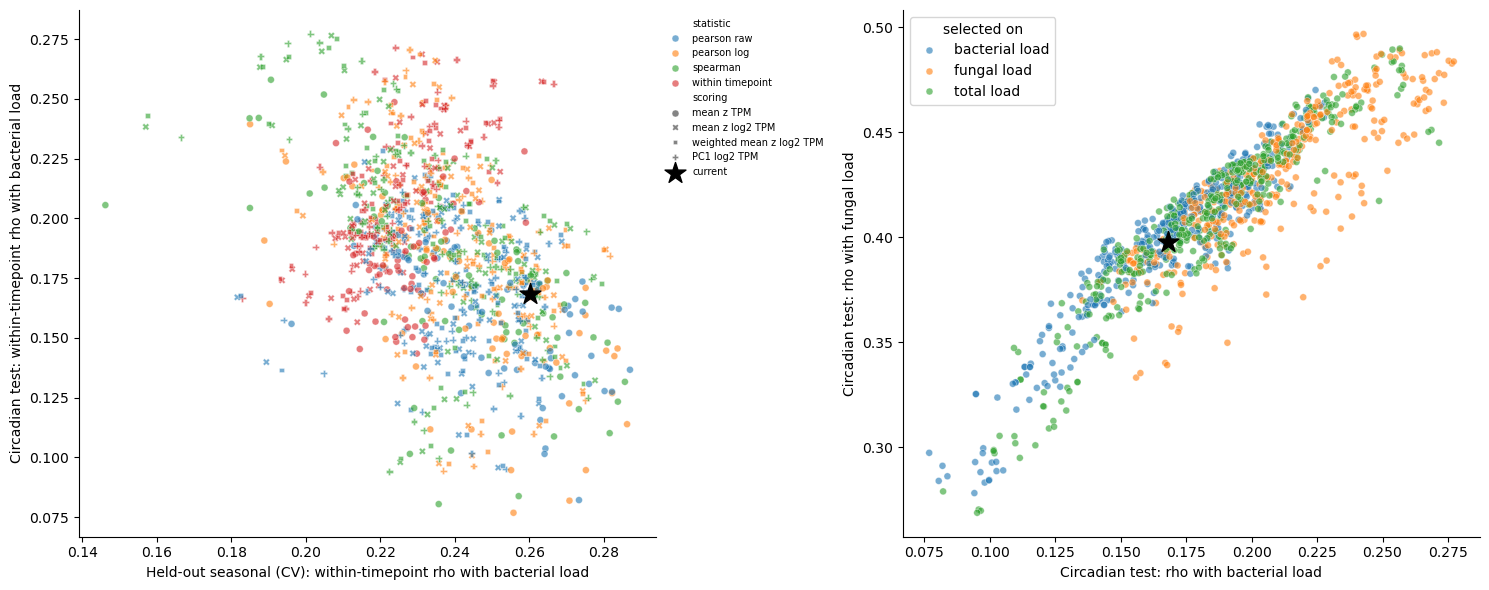

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
fig.patch.set_facecolor("white")
plot_df = defense_only.dropna(subset=["CV bacterial", "circadian bacterial"])
sns.scatterplot(data=plot_df, x="CV bacterial", y="circadian bacterial", hue="statistic", style="scoring", alpha=0.6, s=25, ax=axes[0])
axes[0].scatter(current_row["CV bacterial"], current_row["circadian bacterial"], s=250, marker="*", color="black", label="current", zorder=5)
axes[0].set_xlabel("Held-out seasonal (CV): within-timepoint rho with bacterial load")
axes[0].set_ylabel("Circadian test: within-timepoint rho with bacterial load")
axes[0].legend(fontsize=7, frameon=False, bbox_to_anchor=(1, 1))
sns.scatterplot(data=plot_df, x="circadian bacterial", y="circadian fungal", hue="selected on", alpha=0.6, s=25, ax=axes[1])
axes[1].scatter(current_row["circadian bacterial"], current_row["circadian fungal"], s=250, marker="*", color="black", zorder=5)
axes[1].set_xlabel("Circadian test: rho with bacterial load")
axes[1].set_ylabel("Circadian test: rho with fungal load")
for ax in axes:
    sns.despine(ax=ax)
plt.tight_layout()

## Candidate scores in detail

The top 3 defense-pool configurations (by held-out bacterial-load correlation), fitted on all seasonal samples and scored on every sample:
- correlation with the current score
- gene overlap with the current 148 genes
- GO biological-process enrichment of genes not in the current set
- defense-score difference (timepoint-adjusted) for the high-defense groupings found earlier: high fungal load, high *Pseudomonas*, and *P. viridiflava* bloom (top 15% within timepoint)

In [13]:
current_score = trimmed_metadata["Defense Score"]
all_samples = trimmed_metadata.index
candidates = {"current (rebuilt)": current_config}
for _, row in ranked.head(3).iterrows():
    kind, value = row["cutoff"].split(" ", 1) if row["cutoff"].startswith("top") else ("r >", row["cutoff"].split(" ")[-1])
    value = float(value) if kind == "r >" else int(value)
    candidates[f"{row['statistic']} | {row['selected on']} | {row['pool']} | {row['cutoff']} | {row['scoring']}"] = (
        row["pool"], row["selected on"], row["statistic"], kind, value, row["scoring"],
    )

candidate_scores = {}
for name, (pool, target, statistic, kind, value, scoring) in candidates.items():
    r_all = correlations["all seasonal"][(target, statistic)]
    genes = select_genes(r_all, pool, kind, value)
    candidate_scores[name] = score_samples(genes, scoring, seasonal, all_samples, r_all)
    pd.Series(sorted(genes), name="gene").to_csv(output_dir / f"genes_{''.join(c if c.isalnum() else '_' for c in name)[:90]}.csv", index=False)
    print(f"{name}: {len(genes)} genes, {len(set(genes) & defense_genes)} in the current 148, "
          f"Spearman with current score {spearmanr(candidate_scores[name], current_score.loc[all_samples])[0]:.2f}")
candidate_scores = pd.DataFrame(candidate_scores)
candidate_scores.to_csv(output_dir / "candidate_scores.csv")

current (rebuilt): 148 genes, 148 in the current 148, Spearman with current score 1.00
within timepoint | total load | FLG | top 25 | PC1 log2 TPM: 25 genes, 8 in the current 148, Spearman with current score 0.82
within timepoint | total load | FLG | top 25 | weighted mean z log2 TPM: 25 genes, 8 in the current 148, Spearman with current score 0.82
within timepoint | total load | FLG | top 25 | mean z log2 TPM: 25 genes, 8 in the current 148, Spearman with current score 0.82


In [14]:
# Do the candidate scores separate the high-defense microbiome groups more clearly?
def top_within_timepoint(score, fraction=0.15):
    z = score.groupby(timepoint.reindex(score.index)).transform(lambda x: (x - x.mean()) / x.std()).fillna(0)
    return z.sort_values(ascending=False).index[: round(fraction * len(z))]


pseudomonas_species = [s for s in species_abundance_matrix.columns if s.startswith("s__Pseudomonas")]
group_definitions = {
    "high fungal load": top_within_timepoint(log_fungal.dropna()),
    "high bacterial load": top_within_timepoint(log_bacterial.dropna()),
    "high Pseudomonas": top_within_timepoint(np.log10(sample_ids.map(species_abundance_matrix[pseudomonas_species].sum(axis=1)) + log_pseudocount).dropna()),
    "P. viridiflava bloom": top_within_timepoint(viridiflava.dropna()),
}
group_rows = []
for group_name, members in group_definitions.items():
    for score_name in candidate_scores.columns:
        df = pd.DataFrame({"y": zscore(candidate_scores[score_name]), "timepoint": timepoint, "high": all_samples.isin(members).astype(float)}, index=all_samples)
        fit = smf.ols("y ~ C(timepoint) + high", data=df).fit()
        group_rows.append({"group": group_name, "score": score_name, "diff (score SD)": fit.params["high"], "t": fit.tvalues["high"], "p": fit.pvalues["high"]})
pd.DataFrame(group_rows).pivot(index="score", columns="group", values="t").round(2)

group,P. viridiflava bloom,high Pseudomonas,high bacterial load,high fungal load
score,,,,
current (rebuilt),2.82,3.06,3.50,2.66
within timepoint | total load | FLG | top 25 | PC1 log2 TPM,4.79,3.58,2.74,4.19
within timepoint | total load | FLG | top 25 | mean z log2 TPM,4.79,3.55,2.75,4.24
within timepoint | total load | FLG | top 25 | weighted mean z log2 TPM,4.79,3.55,2.75,4.23


In [15]:
background = log_tpm.columns.tolist()
for name, (pool, target, statistic, kind, value, scoring) in list(candidates.items())[1:]:
    genes = select_genes(correlations["all seasonal"][(target, statistic)], pool, kind, value)
    new_genes = sorted(set(genes) - defense_genes)
    print(f"\n=== {name}: {len(new_genes)} genes not in the current 148 ===")
    if len(new_genes) < 10:
        continue
    with contextlib.redirect_stdout(io.StringIO()), contextlib.redirect_stderr(io.StringIO()):
        tables = Go_tools.generate_contigency_tables(go_annotations=go_term_matrix, gene_list=new_genes, use_background_genes=True, background_genes=background)
        go_results = Go_tools.multi_hypothesis_correct_fishers_exact(
            Go_tools.fishers_exact_on_contigency_tables(all_go_contigency_tables=tables, original_GO_term_panda=go_term_matrix)
        )
    display(go_results.merge(go_term_names, left_index=True, right_index=True, how="left").sort_values("P_value").head(10))


=== within timepoint | total load | FLG | top 25 | PC1 log2 TPM: 17 genes not in the current 148 ===


,P_value,x
GO:0000001,1.0,mitochondrion inheritance
GO:0000009,1.0,"alpha-1,6-mannosyltransferase activity"
GO:0000012,1.0,single strand break repair
GO:0000014,1.0,single-stranded DNA endodeoxyribonuclease acti...
GO:0000023,1.0,maltose metabolic process
GO:0000024,1.0,maltose biosynthetic process
GO:0000025,1.0,maltose catabolic process
GO:0000026,1.0,"alpha-1,2-mannosyltransferase activity"
GO:0000027,1.0,ribosomal large subunit assembly
GO:0000028,1.0,ribosomal small subunit assembly



=== within timepoint | total load | FLG | top 25 | weighted mean z log2 TPM: 17 genes not in the current 148 ===


,P_value,x
GO:0000001,1.0,mitochondrion inheritance
GO:0000009,1.0,"alpha-1,6-mannosyltransferase activity"
GO:0000012,1.0,single strand break repair
GO:0000014,1.0,single-stranded DNA endodeoxyribonuclease acti...
GO:0000023,1.0,maltose metabolic process
GO:0000024,1.0,maltose biosynthetic process
GO:0000025,1.0,maltose catabolic process
GO:0000026,1.0,"alpha-1,2-mannosyltransferase activity"
GO:0000027,1.0,ribosomal large subunit assembly
GO:0000028,1.0,ribosomal small subunit assembly



=== within timepoint | total load | FLG | top 25 | mean z log2 TPM: 17 genes not in the current 148 ===


,P_value,x
GO:0000001,1.0,mitochondrion inheritance
GO:0000009,1.0,"alpha-1,6-mannosyltransferase activity"
GO:0000012,1.0,single strand break repair
GO:0000014,1.0,single-stranded DNA endodeoxyribonuclease acti...
GO:0000023,1.0,maltose metabolic process
GO:0000024,1.0,maltose biosynthetic process
GO:0000025,1.0,maltose catabolic process
GO:0000026,1.0,"alpha-1,2-mannosyltransferase activity"
GO:0000027,1.0,ribosomal large subunit assembly
GO:0000028,1.0,ribosomal small subunit assembly
